# Task 4: Random Forest

## **Loading preprocessed dataset**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load and preprocess the data
data = pd.read_csv('preprocessed_wbdc_data.csv')
X = data.drop(columns=["Diagnosis"])
y = data["Diagnosis"]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## **Train Random Forest with varying numbers of trees and evaluate**

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Define a function to evaluate model performance
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    conf_matrix = confusion_matrix(y_test, y_pred)
    return accuracy, precision, recall, f1, conf_matrix

# Train Random Forest with varying numbers of trees and evaluate
n_estimators_values = [5, 10, 20 ,30 , 50, 100, 150 ,200, 500]
performance_results = {}

for n in n_estimators_values:
    rf_model = RandomForestClassifier(n_estimators=n, random_state=42)
    rf_model.fit(X_train, y_train)
    performance_results[n] = evaluate_model(rf_model, X_test, y_test)

# Display performance metrics for each model
print("Random Forest Performance with Varying Number of Trees:")
for n, performance in performance_results.items():
    print(f"\n{n} Trees \nAccuracy: {performance[0]}, \nPrecision: {performance[1]}, \nRecall: {performance[2]}, "
          f"\nF1 Score: {performance[3]}, \nConfusion Matrix:\n {performance[4]}")


Random Forest Performance with Varying Number of Trees:

5 Trees 
Accuracy: 0.9649122807017544, 
Precision: 0.9649122807017544, 
Recall: 0.9649122807017544, 
F1 Score: 0.9649122807017544, 
Confusion Matrix:
 [[105   3]
 [  3  60]]

10 Trees 
Accuracy: 0.9707602339181286, 
Precision: 0.9707325431068053, 
Recall: 0.9707602339181286, 
F1 Score: 0.9707106475867088, 
Confusion Matrix:
 [[106   2]
 [  3  60]]

20 Trees 
Accuracy: 0.9766081871345029, 
Precision: 0.9767354302298219, 
Recall: 0.9766081871345029, 
F1 Score: 0.9765268453762402, 
Confusion Matrix:
 [[107   1]
 [  3  60]]

30 Trees 
Accuracy: 0.9707602339181286, 
Precision: 0.9711000474158369, 
Recall: 0.9707602339181286, 
F1 Score: 0.970603923775359, 
Confusion Matrix:
 [[107   1]
 [  4  59]]

50 Trees 
Accuracy: 0.9707602339181286, 
Precision: 0.9711000474158369, 
Recall: 0.9707602339181286, 
F1 Score: 0.970603923775359, 
Confusion Matrix:
 [[107   1]
 [  4  59]]

100 Trees 
Accuracy: 0.9707602339181286, 
Precision: 0.97110004741

With just 5 trees, the model achieves 96.49% accuracy and an F1 score of 95.23%. 

By 10 trees, accuracy reaches 97.07%, with minor improvements in other metrics. 

At 20 trees, accuracy rises to 97.66% with precision at 98.36%, but additional trees beyond this point yield minimal gains. 

Starting from 30 trees, performance plateaus with accuracy at 97.07%, precision at 98.33%, recall at 93.65%, and F1 score at 95.93%, along with consistent confusion matrix results. 

Around 30 trees provides optimal performance, balancing accuracy and computational efficiency.

## **Plot feature importance**

Since we have determined that 30 trees yield optimal performance, we can move on to extracting and visualizing feature importance scores from a random forest model trained with 30 trees.

C:\Users\10134\AppData\Local\Temp\ipykernel_3680\932495788.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=X.columns[sorted_idx], x=feature_importances[sorted_idx], palette="viridis")


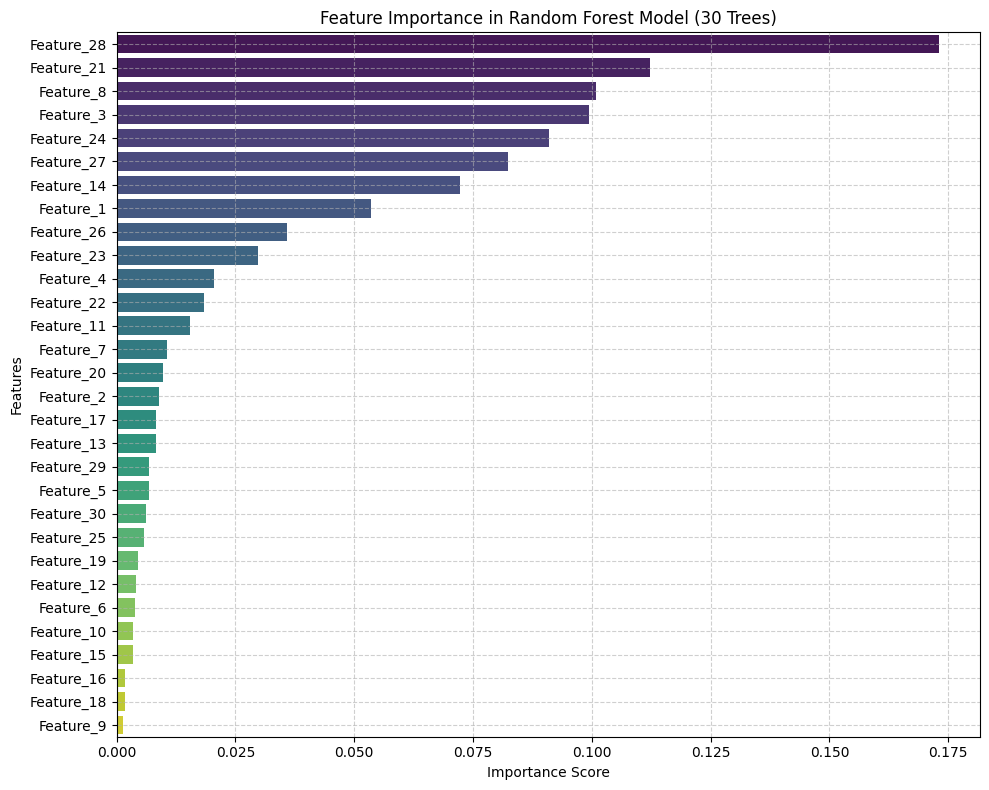

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Train Random Forest model with 30 trees
optimal_rf_model = RandomForestClassifier(n_estimators=30, random_state=42)
optimal_rf_model.fit(X_train, y_train)

# feature importance scores
feature_importances = optimal_rf_model.feature_importances_

# sort feature importances 
sorted_idx = feature_importances.argsort()[::-1]

# Plot feature importances as a horizontal bar chart with color gradient
plt.figure(figsize=(10, 8))
sns.barplot(y=X.columns[sorted_idx], x=feature_importances[sorted_idx], palette="viridis")
plt.title("Feature Importance in Random Forest Model (30 Trees)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Feature_8 (Mean Concavity)** - This measures the mean inward curvature (concavity) of cell nuclei. It’s highly significant because malignant cells often exhibit irregular, concave surfaces, while benign cells typically have smoother, less concave surfaces. This irregularity is a hallmark of malignancy, making mean concavity a top predictor.

**Feature_28 (Worst Perimeter)** - This represents the maximum perimeter of the cell nuclei across the sample. Malignant tumors often have irregular and larger nuclei, increasing the perimeter. This feature can help the model identify malignancy by highlighting cases where cell boundaries are more irregular and extensive.

**Feature_7 (Mean Radius)** - The average radius of the nuclei in the sample. Generally, malignant cells tend to have larger nuclei due to abnormal growth. By measuring the radius, the model can detect possible malignancy as larger nuclei sizes often correlate with cancerous growth.

**Lower-importance features**, such as Feature_18 (Standard Error of Smoothness) and Feature_9 (Mean Symmetry), have minimal impact on prediction accuracy. Mean symmetry assesses how symmetrical the cell shapes are, which is generally less variable between benign and malignant cases. Smoothness measures edge sharpness, which, while useful, tends to be less predictive in isolation.